# F01 能量账本、单位与闭合复核

**课程修订P1-1；分析核心0.1.0。跟随操作：入门；独立解释：进阶。**

先修：代数、正负号、单位。解释真实电子态或不同几何的比较，还需要方法、状态、算符及参考条件知识。本课L1—L3全部为**合成数学账本**，不是实测数据，也不是新量子计算或分子图预测。

目标：核对来源和单位，理解组成、参考与闭合残差，区分程序执行完成、科学检查失败和输入拒绝。阅读版保存真实表格与图；GitHub预览不执行Python。

交互运行：按课程包README准备依赖，从头运行。无需平台令牌、AI密钥或Docker。原代码的Colab准备单元默认关闭；已验交互入口是独立Colab适配版，具体完成与未验收范围见页首。

## 当前课程状态

五课已完成从GitHub首页进入新版Colab、私有依赖安装、默认/修改参数共10轮从头运行、手工参数修改、结果重载及Drive保存复开。五份原生Notebook和五份独立结果ZIP下载均已验收；Notebook内嵌ZIP、独立下载ZIP与本次云端附件逐字节一致，SHA-256及结果清单核对通过。环境准备长代码默认折叠，课程标题无括号日期。新RHF继续未验收（NOT_EXECUTED）。

本次只同步完成状态、导航和验收摘要，科学代码、样本、内置wheel、运行器及保存输出不变。内置原课和科学输出中的旧状态文字是历史快照，最新完成范围以本说明及docs/STATUS.md为准；FAIL、DIAGNOSTIC与NOT_ASSESSED边界不变。

GitHub用于在线阅读，Colab用于交互运行。Binder、其它账号或环境、试学及学习者独立解释能力仍未验收。旧Drive副本不自动更新，请从课程首页打开新版入口。

[课程首页](../README.md) · [交互运行说明](../docs/RUNNING.md) · [完成与未验收范围](../docs/STATUS.md)

## 学习与验收范围

五课已完成真实Colab默认/修改参数共10轮运行、私有依赖安装、手工参数修改、结果重载及Drive另存副本。五份原生下载的Notebook已核验；其内嵌结果ZIP均与云端结果逐字节一致。单独点击ZIP链接下载仍未验；新RHF仍未验收（NOT_EXECUTED）。

本次仅更新公开导航和状态文字，不改变科学代码、样本、内置wheel及运行器。保存的科学输出和Colab内置原课中的旧状态文字属于历史快照，以本页说明及docs/STATUS.md为准；FAIL、DIAGNOSTIC及NOT_ASSESSED边界不变。

GitHub只显示静态内容；交互计算使用独立Colab适配。公开页面/固定ref入口首次同步后单独核对；Binder、其它账号/环境、试学与独立解释能力未验收。

[五课入口](../README.md) · [本课Colab适配](../colab/F01-colab.ipynb)

In [1]:
PREPARE_COLAB = False
if PREPARE_COLAB:
    import hashlib, json, os, subprocess, sys, uuid, zipfile
    from pathlib import Path, PurePosixPath
    from google.colab import files
    if sys.version_info < (3,12):
        raise RuntimeError("本课核心要求Python 3.12或更新版本；当前云端环境未验收。")
    uploaded = files.upload()
    if len(uploaded) != 1:
        raise ValueError("请选择本课一个ZIP；不要上传私有资料。")
    filename = next(iter(uploaded))
    target = Path("f01-cloud-" + uuid.uuid4().hex)
    target.mkdir(exist_ok=False)
    with zipfile.ZipFile(filename) as z:
        for item in z.infolist():
            name = PurePosixPath(item.filename)
            if name.is_absolute() or ".." in name.parts or ":" in item.filename or "\\" in item.filename or (item.external_attr >> 16) & 0o170000 == 0o120000:
                raise ValueError("ZIP包含非法路径或链接")
        if sum(i.file_size for i in z.infolist()) > 32*1024*1024:
            raise ValueError("ZIP解包内容超出课程预算")
        z.extractall(target)
    record = json.loads((target / "lesson-manifest.json").read_text("utf-8"))
    for item in record["inputs"] + [record["wheel"]]:
        rel = PurePosixPath(item["file"])
        if rel.is_absolute() or ".." in rel.parts or ":" in item["file"] or "\\" in item["file"]:
            raise ValueError("课程清单路径非法")
        if hashlib.sha256((target / item["file"]).read_bytes()).hexdigest() != item["sha256"]:
            raise ValueError("课程文件哈希不符")
    subprocess.check_call([sys.executable,"-m","pip","install","-r","requirements.txt"], cwd=target)
    os.chdir(target)
    print("课程文件已准备；必要时按Colab提示重启后重新准备。云端验收尚未执行。")
else:
    print("云端安装关闭；本地按导学准备依赖后顺序运行。")


云端安装关闭；本地按导学准备依赖后顺序运行。


## 1. 载入样本与来源清单

只读取课程内固定文件并核对SHA-256。保留原始样本，每次运行另建输出目录。分项和参考在来源JSON的不同字段中；字段分开并不构成独立实验认证。

几何哈希全零及NOT_APPLICABLE标签仅说明合成例的占位身份，不能当作真实分子几何资格。

In [2]:
import copy, hashlib, json, uuid
from decimal import Decimal
from pathlib import Path
import numpy as np
from IPython.display import display, HTML, Image
from ai4orgchem_data_processing.analysis import analyze, run_analysis

roots=[p for base in (Path.cwd(),*Path.cwd().parents)
       for p in (base,base/"learning/energy_ledger")
       if (p/"lesson-manifest.json").is_file()
       and json.loads((p/"lesson-manifest.json").read_text("utf-8")).get("lesson")=="F01"]
if not roots:raise FileNotFoundError("请从本课解压目录或项目内启动；先查看导学。")
lesson_root=roots[0]
manifest=json.loads((lesson_root/"lesson-manifest.json").read_text("utf-8"))
for item in manifest["inputs"]:
    assert hashlib.sha256((lesson_root/item["file"]).read_bytes()).hexdigest()==item["sha256"]
samples=lesson_root/"samples"
workspace=lesson_root/"outputs"/("study-"+uuid.uuid4().hex)
workspace.mkdir(parents=True,exist_ok=False)
def request(name):return json.loads((samples/(name+".json")).read_text("utf-8"))
def raw(task):return json.dumps(task,ensure_ascii=False,allow_nan=False).encode("utf-8")
print("合成教学样本；文件哈希PASS；本次使用全新课程内输出目录。")

合成教学样本；文件哈希PASS；本次使用全新课程内输出目录。


## 2. 有符号组成与独立列出的参考

L1三个分项为-1、+0.25、+0.5 Eh，参考为-0.25 Eh。系数和参考必须显式给出，不由本次求和自动生成唯一答案。

$$E_{assembled}=\sum_i c_i E_i=-1+0.25+0.5=-0.25\ \mathrm{Eh}$$

来源JSON及字段路径、方法/状态/协议等元数据由输入合同检查。这里的“独立列出”是算术基准组织方式，不是第二种量子方法或实验的独立验证。

In [3]:
task=request("L1")
report=run_analysis(raw(task),samples,workspace/"main")
assert report.exit_code==0 and report.analysis_status=="PASS"
row=report.results["compositions"][0]
reference=Decimal("-0.25")
assert sum([Decimal("-1"),Decimal("0.25"),Decimal("0.5")])==reference
assert Decimal(row["assembled_hartree"])==reference
assert Decimal(row["reference_hartree"])==reference and Decimal(row["residual_hartree"])==0
table="<table><tr><th>项</th><th>原值</th><th>单位</th><th>来源字段</th></tr>"
for term in task["data"]["terms"]+task["data"]["references"]:
    table+=f"<tr><td>{term['id']}</td><td>{term['value']}</td><td>{term['unit']}</td><td>{term['source']['field']}</td></tr>"
display(HTML(table+"</table>"))
print("L1：组成=-0.25 Eh；参考=-0.25 Eh；残差=0 Eh；PASS。")

项,原值,单位,来源字段
part0,-1,hartree,/part0
part1,0.25,hartree,/part1
part2,0.5,hartree,/part2
part3,-0.25,hartree,/part3


L1：组成=-0.25 Eh；参考=-0.25 Eh；残差=0 Eh；PASS。


## 3. 残差、容差与单位换算

$$r=E_{assembled}-E_{reference},\qquad |r|\leq10^{-9}\ \mathrm{Eh}$$

闭合采用冻结绝对容差1e-9 Eh，相对容差为0。容差不是测量不确定度；数值闭合也不证明分解物理唯一或状态比较合理。

L2包含1 kcal/mol和-4.184 kJ/mol，先换成相同单位再相加。采用冻结adp-units-v1常数，不改原值。

$$1\ \mathrm{kcal/mol}=4.184\ \mathrm{kJ/mol},\qquad 1\ \mathrm{Eh}=2625.4996394799\ \mathrm{kJ/mol}$$

In [4]:
mixed_task=request("L2")
mixed=run_analysis(raw(mixed_task),samples,workspace/"mixed")
assert mixed.analysis_status=="PASS"
mixed_row=mixed.results["compositions"][0]
assert abs(Decimal(mixed_row["residual_hartree"]))<Decimal("1e-40")
assert Decimal("1")*Decimal("4.184")+Decimal("-4.184")==0
table="<table><tr><th>项</th><th>原值与单位</th><th>归一值 (Eh)</th></tr>"
for term in mixed_task["data"]["terms"]:
    value=mixed.results["terms"][term["id"]]["hartree"]["target_value"]
    table+=f"<tr><td>{term['id']}</td><td>{term['value']} {term['unit']}</td><td>{float(value):.10g}</td></tr>"
display(HTML(table+"</table>"))
print("L2：归一后闭合；不能直接把不同单位的1与-4.184相加。")

项,原值与单位,归一值 (Eh)
part0,1 kcal/mol,0.001593601438
part1,-4.184 kJ/mol,-0.001593601438


L2：归一后闭合；不能直接把不同单位的1与-4.184相加。


## 4. 漏项：执行成功，检查FAIL

L3漏掉+0.5 Eh，组成变为-0.75 Eh，对-0.25 Eh参考的残差为-0.5 Eh，远超容差。任务能完成运算并保存文件，但检查必须FAIL。不能因希望界面全绿而补项、改参考或放宽门槛。

In [5]:
failed=run_analysis(raw(request("L3-fails-closure")),samples,workspace/"missing-term")
assert failed.execution_status=="SUCCEEDED" and failed.analysis_status=="FAIL" and failed.exit_code==4
failed_row=failed.results["compositions"][0]
assert Decimal(failed_row["assembled_hartree"])==Decimal("-0.75")
assert Decimal(failed_row["residual_hartree"])==Decimal("-0.5")
print("L3：执行SUCCEEDED；闭合FAIL；残差=-0.5 Eh；退出码4（预期科学检查失败）。")

L3：执行SUCCEEDED；闭合FAIL；残差=-0.5 Eh；退出码4（预期科学检查失败）。


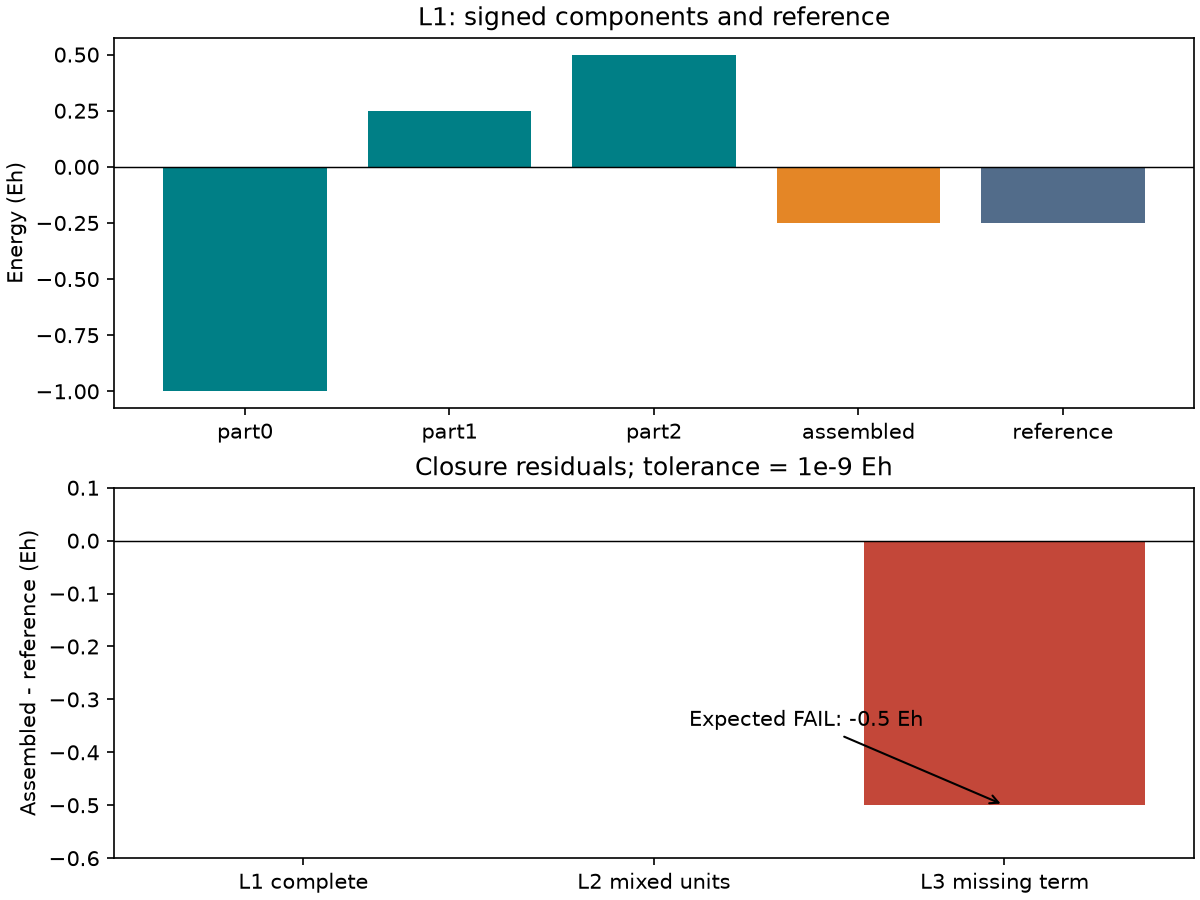

In [6]:
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
fig=Figure(figsize=(8,6),layout="constrained");FigureCanvasAgg(fig)
top,bottom=fig.subplots(2,1)
parts=[float(report.results["terms"][term["id"]]["hartree"]["target_value"]) for term in task["data"]["terms"]]
top.bar(["part0","part1","part2","assembled","reference"],parts+[float(row["assembled_hartree"]),float(row["reference_hartree"])],color=["#007f86"]*3+["#e48626","#526c8a"])
top.axhline(0,color="black",linewidth=.7);top.set_ylabel("Energy (Eh)");top.set_title("L1: signed components and reference")
residuals=[float(x["residual_hartree"]) for x in [row,mixed_row,failed_row]]
bottom.bar(["L1 complete","L2 mixed units","L3 missing term"],residuals,color=["#007f86","#007f86","#c34739"])
bottom.axhline(0,color="black",linewidth=.7);bottom.set_ylabel("Assembled - reference (Eh)")
bottom.set_ylim(-.6,.1);bottom.set_title("Closure residuals; tolerance = 1e-9 Eh")
bottom.annotate("Expected FAIL: -0.5 Eh",xy=(2,-.5),xytext=(1.1,-.35),arrowprops={"arrowstyle":"->"})
fig.savefig(workspace/"ledger-and-closure.png",dpi=150)
display(Image(filename=str(workspace/"ledger-and-closure.png")))

上图各柱均为Eh，分别显示带符号分项、组成和参考，不是能量轨迹。下图显示归一后的闭合残差；L3的负号表示组成比参考更负。1e-9 Eh容差在该纵轴尺度下不可见，应读数值断言，不能凭图判断微小残差。

## 5. 输入拒绝：不能算的就拒绝

重复项属于非法组成；协议不一致属于不可比较；来源字节被改动而哈希未更新属于完整性失败。它们不同于L3这种合法输入的闭合FAIL。篡改示例只操作新建副本，不改samples。

In [7]:
rejections=[]
for label,change,expected in [
    ("重复项",lambda t:t["data"]["compositions"][0]["components"].append(copy.deepcopy(t["data"]["compositions"][0]["components"][0])),"INVALID_INDEX"),
    ("协议冲突",lambda t:t["data"]["states"][0].update(protocol_version="other"),"INCOMPATIBLE_COMPARISON")]:
    bad=copy.deepcopy(task);change(bad);rejected=analyze(raw(bad),samples)
    assert rejected.execution_status=="REJECTED" and rejected.analysis_status=="NOT_EXECUTED"
    assert rejected.errors[0]["code"]==expected
    rejections.append(expected);print(label+"："+expected)
tampered=workspace/"tampered-inputs";tampered.mkdir(exist_ok=False)
(tampered/"L1-source.json").write_bytes((samples/"L1-source.json").read_bytes()+b" ")
rejected=analyze(raw(task),tampered)
assert rejected.execution_status=="REJECTED" and rejected.analysis_status=="NOT_EXECUTED"
assert rejected.errors[0]["code"]=="HASH_MISMATCH"
rejections.append("HASH_MISMATCH");print("来源哈希冲突：HASH_MISMATCH")

重复项：INVALID_INDEX
协议冲突：INCOMPATIBLE_COMPARISON
来源哈希冲突：HASH_MISMATCH


## 6. 交互练习：故意漏掉最后一个分项

先预测，再将OMIT_LAST_TERM由False改为True并从头运行。组成应由-0.25变成-0.75 Eh，残差由0变为-0.5 Eh，检查从PASS变为FAIL。保留参考不变，不能自动修复这个失败；原样本也不改变。

若改成True，下面单元仍会顺利完成，因为断言的是“按预期FAIL”，不是把失败结果判为科学通过。

In [8]:
OMIT_LAST_TERM = False
assert isinstance(OMIT_LAST_TERM,bool)
explore=copy.deepcopy(task)
if OMIT_LAST_TERM:explore["data"]["compositions"][0]["components"].pop()
explore["provenance"]["description"]="合成账本的显式漏项练习；原参考不变，不是新科学计算"
explored=run_analysis(raw(explore),samples,workspace/"explore")
expected_status="FAIL" if OMIT_LAST_TERM else "PASS"
expected_residual=Decimal("-0.5") if OMIT_LAST_TERM else Decimal("0")
assert explored.execution_status=="SUCCEEDED" and explored.analysis_status==expected_status
assert explored.exit_code==(4 if OMIT_LAST_TERM else 0)
assert Decimal(explored.results["compositions"][0]["residual_hartree"])==expected_residual
print(f"漏项开关={OMIT_LAST_TERM}；检查={expected_status}；残差={expected_residual} Eh。")

漏项开关=False；检查=PASS；残差=0 Eh。


## 7. 保存、重载与下载

四组结果main、mixed、missing-term、explore均保存请求、来源快照、结果、报告、图表与哈希清单，包括预期FAIL。下面逐组从保存请求重载，核对结果和哈希，再打包成ZIP。

Jupyter用文件浏览器下载ZIP，另行保存修改后的Notebook。Colab下载单元默认关闭，只有显式打开后才调用下载；运行时文件不等于永久保存。

In [9]:
import zipfile
for name,original in [("main",report),("mixed",mixed),("missing-term",failed),("explore",explored)]:
    saved=workspace/name
    reloaded=run_analysis((saved/"request.json").read_bytes(),saved/"inputs",workspace/("reload-"+name))
    assert reloaded.results==original.results and reloaded.analysis_status==original.analysis_status
    for item in json.loads((saved/"manifest.json").read_text("utf-8")):
        assert hashlib.sha256((saved/item["file"]).read_bytes()).hexdigest()==item["sha256"]
summary={"lesson":"F01","analysis":"PASS","expected_failure":"FAIL","rejections":rejections,
         "reload_equal":True,"omit_last_term":OMIT_LAST_TERM,"explore_analysis":expected_status,
         "explore_residual":str(expected_residual),"new_quantum_calls":0,"teaching_effectiveness":"NOT_EVALUATED"}
(workspace/"lesson-result.json").write_text(json.dumps(summary,ensure_ascii=False,indent=2)+"\n",encoding="utf-8")
archive=workspace/"energy-ledger-results.zip"
with zipfile.ZipFile(archive,"x",compression=zipfile.ZIP_DEFLATED) as z:
    for name in ["main","mixed","missing-term","explore"]:
        for item in sorted((workspace/name).rglob("*")):
            if item.is_file():z.write(item,item.relative_to(workspace).as_posix())
    for name in ["ledger-and-closure.png","lesson-result.json"]:z.write(workspace/name,name)
print("四组结果重载及哈希核对PASS；已保存energy-ledger-results.zip。")
print("新量子计算调用：0；漏项结果仍保留FAIL；教学效果未评价。")

四组结果重载及哈希核对PASS；已保存energy-ledger-results.zip。
新量子计算调用：0；漏项结果仍保留FAIL；教学效果未评价。


In [10]:
DOWNLOAD_IN_COLAB = False
if DOWNLOAD_IN_COLAB:
    from google.colab import files
    files.download(str(archive))
else:
    print("自动下载关闭；在课程outputs的新study目录下载energy-ledger-results.zip。")

自动下载关闭；在课程outputs的新study目录下载energy-ledger-results.zip。


## 8. 独立解释与参考

先回答：①L3程序完成和检查FAIL矛盾吗？②不同单位能直接相加吗？③来源字段不同能证明独立科学证据吗？④闭合能证明分解唯一吗？

参考：①不矛盾，完成运算不代表满足比较条件；②先归一并保留原值/换算因子；③不能，仍需审查原计算或测量来源；④不能，只复核明确组成、参考和比较合同。

同一表示比较要求几何、方法、基组、状态、算符和映射相容；几何响应只允许合同声明的几何差异，其余条件仍须核对。本课不通过添加一个不同态或不同方法的数字来解释真实物理差异。

**练习交付**：修改漏项开关，运行并提交Notebook和ZIP，用文字解释FAIL为何是正确结果。自动测试只验证数值与拒绝语义，不评价独立解释能力。

来源：项目合成L1/L2/L3、adp-numerical-v1及ADP-IMPLEMENTATION-1.0；样本、原Notebook和核心wheel哈希见课程清单。范围不含图匹配、新RHF、任意条件态分解或理论唯一性认证。